In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [3]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# Random Forest

Device: cuda
Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 230MB/s] 



Epoch 1/50


...

Validation Loss: 0.4779 (CE: 0.5374, Dice: 0.4184), Validation Accuracy: 0.6578
  -> No improvement for 7/8 epochs

Epoch 15/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.16s/it]


Train Loss: 0.4768 (CE: 0.5478, Dice: 0.4058), Train Accuracy: 0.7203


Validating: 100%|██████████| 5/5 [00:04<00:00,  1.03it/s]


Validation Loss: 0.4727 (CE: 0.5252, Dice: 0.4202), Validation Accuracy: 0.7328
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 15. Best Validation Accuracy: 0.7531

Training completed in time: 0:07:05.900613

Best VGG16 Validation Accuracy: 0.7531


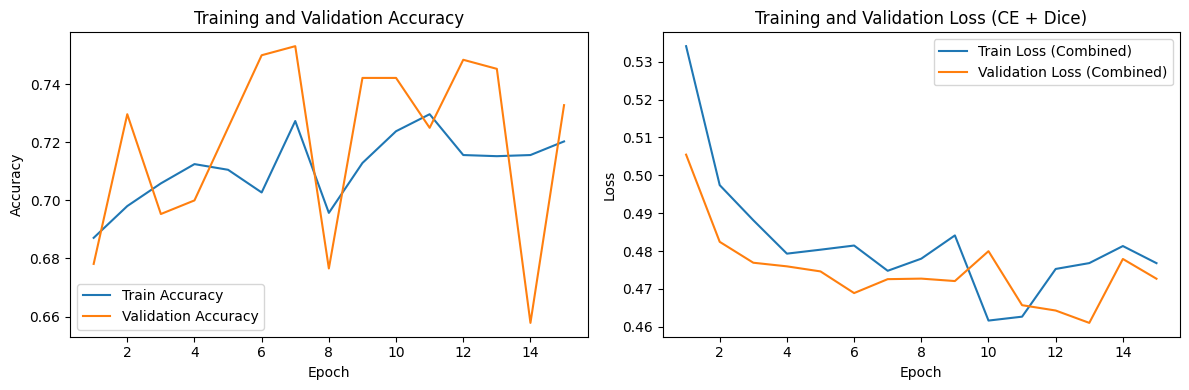

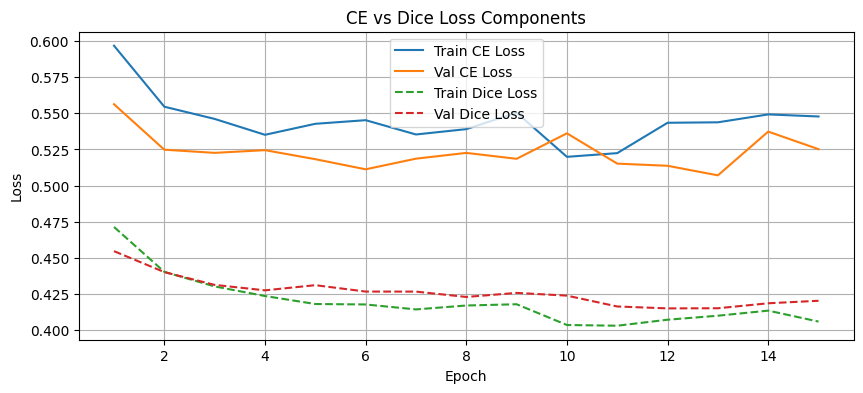


EXTRACTING VGG16 FEATURES


Extracting Features: 100%|██████████| 12/12 [00:11<00:00,  1.05it/s]



Train feature shape: (2560, 4096)
Validation feature shape: (640, 4096)
Test feature shape: (1468, 4096)

TRAINING RANDOM FOREST
Random Forest training completed.

Random Forest Validation Accuracy: 0.7203
Random Forest Test Accuracy: 0.7473

Random Forest Precision (weighted): 0.8021
Random Forest Recall (weighted):    0.7473
Random Forest F1-score (weighted):  0.6663

Random Forest Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.74      1.00      0.85      1052
  Appears normal       0.96      0.11      0.20       416

        accuracy                           0.75      1468
       macro avg       0.85      0.56      0.53      1468
    weighted avg       0.80      0.75      0.67      1468

Random Forest Confusion Matrix:
[[1050    2]
 [ 369   47]]


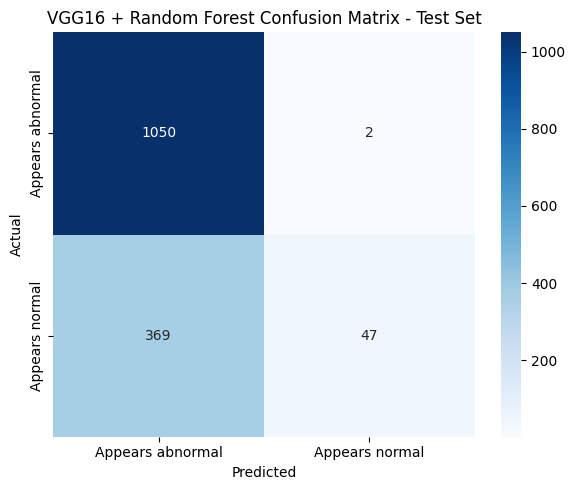

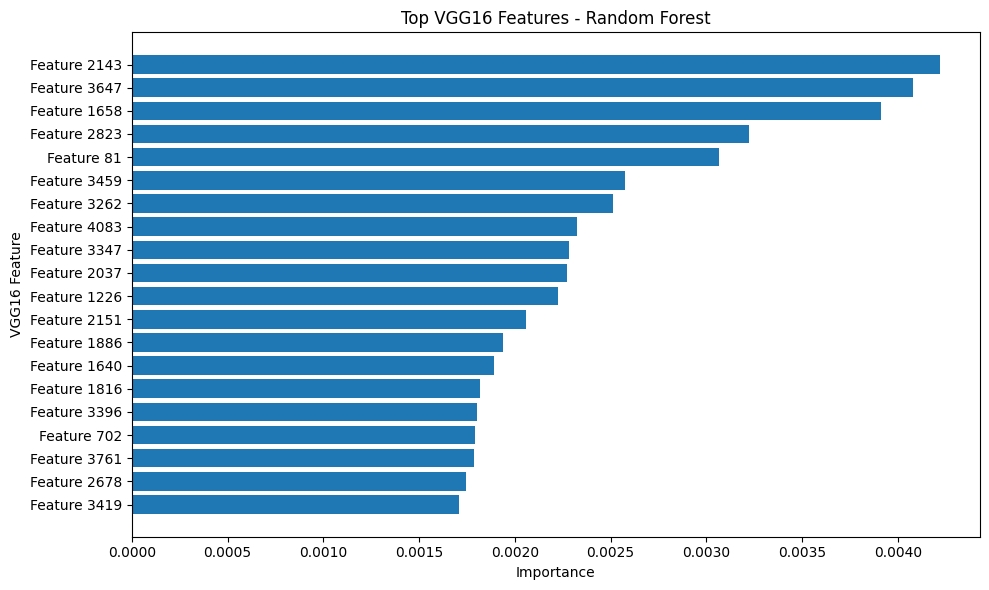


FINAL SUMMARY
Best VGG16 Validation Accuracy: 0.7531
Random Forest Validation Accuracy: 0.7203
Random Forest Test Accuracy: 0.7473
Random Forest Test Precision: 0.8021
Random Forest Test Recall: 0.7473
Random Forest Test F1-score: 0.6663

Feature Dimension: 4096

Model Flow:
Input Image -> VGG16 -> 4096-D Features -> Random Forest -> Prediction


In [21]:
# ============================================================
# IMPORTS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tqdm import tqdm
from datetime import datetime
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# PATHS
# ============================================================

train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# PREPROCESSING
# ============================================================

data_transforms = {

    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}


# ============================================================
# LOAD DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    train_path,
    transform=data_transforms['train']
)

train_dataset_val = datasets.ImageFolder(
    train_path,
    transform=data_transforms['val']
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=data_transforms['test']
)


# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

train_subset = Subset(
    train_dataset,
    train_indices
)

val_subset = Subset(
    train_dataset_val,
    val_indices
)


# ============================================================
# DATALOADERS
# ============================================================

batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)


# ============================================================
# DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth)
            /
            (union + self.smooth)
        )

        return 1. - dice_score.mean()


# ============================================================
# COMBINED LOSS
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# ACCURACY FUNCTION
# ============================================================

def calculate_accuracy(
    y_pred,
    y_true
):

    _, predicted = torch.max(
        y_pred,
        1
    )

    correct = (
        predicted == y_true
    ).sum().item()

    return correct / len(y_true)


# ============================================================
# VGG16 MODEL
# ============================================================

vgg = models.vgg16(
    pretrained=True
)


# Freeze VGG layers

for param in vgg.parameters():
    param.requires_grad = False


# Replace final classifier

vgg.classifier[6] = nn.Linear(
    vgg.classifier[6].in_features,
    num_classes
)


# Move to device

vgg = vgg.to(device)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    vgg.classifier[6].parameters()
)


# ============================================================
# TRAINING SETTINGS
# ============================================================

overall_best_accuracy = 0.0

model_save_path = 'best_vgg_model.pth'

patience = 8

num_epochs = 50


# ============================================================
# GRAPH DATA
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EARLY STOPPING
# ============================================================

best_val_accuracy = 0.0

epochs_no_improve = 0


# ============================================================
# TRAINING
# ============================================================

start = datetime.now()


for epoch in range(num_epochs):

    print("\n" + "=" * 60)

    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print("=" * 60)


    # ========================================================
    # TRAINING PHASE
    # ========================================================

    vgg.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0
    running_accuracy = 0.0


    for inputs, labels_batch in tqdm(
        train_loader,
        desc='Training'
    ):

        inputs = inputs.to(device)

        labels_batch = labels_batch.to(device)


        optimizer.zero_grad()


        outputs = vgg(inputs)


        loss, ce, dice = criterion(
            outputs,
            labels_batch
        )


        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        running_ce += ce.item()

        running_dice += dice.item()

        running_accuracy += calculate_accuracy(
            outputs,
            labels_batch
        )


    epoch_train_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_train_ce = (
        running_ce /
        len(train_loader)
    )

    epoch_train_dice = (
        running_dice /
        len(train_loader)
    )

    epoch_train_accuracy = (
        running_accuracy /
        len(train_loader)
    )


    train_losses.append(
        epoch_train_loss
    )

    train_ce_losses.append(
        epoch_train_ce
    )

    train_dice_losses.append(
        epoch_train_dice
    )

    train_accuracies.append(
        epoch_train_accuracy
    )


    print(
        f"Train Loss: {epoch_train_loss:.4f} "
        f"(CE: {epoch_train_ce:.4f}, "
        f"Dice: {epoch_train_dice:.4f}), "
        f"Train Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )


    # ========================================================
    # VALIDATION PHASE
    # ========================================================

    vgg.eval()

    val_loss = 0.0
    val_ce = 0.0
    val_dice = 0.0
    val_accuracy = 0.0


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            val_loader,
            desc='Validating'
        ):

            inputs = inputs.to(device)

            labels_batch = labels_batch.to(device)


            outputs = vgg(inputs)


            loss, ce, dice = criterion(
                outputs,
                labels_batch
            )


            val_loss += loss.item()

            val_ce += ce.item()

            val_dice += dice.item()

            val_accuracy += calculate_accuracy(
                outputs,
                labels_batch
            )


    epoch_val_loss = (
        val_loss /
        len(val_loader)
    )

    epoch_val_ce = (
        val_ce /
        len(val_loader)
    )

    epoch_val_dice = (
        val_dice /
        len(val_loader)
    )

    epoch_val_accuracy = (
        val_accuracy /
        len(val_loader)
    )


    val_losses.append(
        epoch_val_loss
    )

    val_ce_losses.append(
        epoch_val_ce
    )

    val_dice_losses.append(
        epoch_val_dice
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    print(
        f"Validation Loss: {epoch_val_loss:.4f} "
        f"(CE: {epoch_val_ce:.4f}, "
        f"Dice: {epoch_val_dice:.4f}), "
        f"Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            epoch_val_accuracy
        )

        epochs_no_improve = 0


        torch.save(
            vgg.state_dict(),
            model_save_path
        )


        print(
            f"  -> Model saved at epoch "
            f"{epoch + 1} with validation "
            f"accuracy {best_val_accuracy:.4f}"
        )


    else:

        epochs_no_improve += 1

        print(
            f"  -> No improvement for "
            f"{epochs_no_improve}/{patience} epochs"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_no_improve >= patience:

        print(
            f"\nEarly stopping triggered at "
            f"epoch {epoch + 1}. "
            f"Best Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )

        break


duration = datetime.now() - start

print(
    "\nTraining completed in time:",
    duration
)


# ============================================================
# LOAD BEST VGG16 MODEL
# ============================================================

vgg.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

vgg = vgg.to(device)

vgg.eval()


print(
    f"\nBest VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)


# ============================================================
# TRAINING & VALIDATION ACCURACY GRAPH
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)


plt.figure(
    figsize=(12, 4)
)


plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    train_accuracies,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracies,
    label='Validation Accuracy'
)

plt.title(
    'Training and Validation Accuracy'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()


# ============================================================
# TRAINING & VALIDATION LOSS GRAPH
# ============================================================

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.title(
    'Training and Validation Loss (CE + Dice)'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# CE VS DICE LOSS
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    epochs_range,
    train_ce_losses,
    label='Train CE Loss'
)

plt.plot(
    epochs_range,
    val_ce_losses,
    label='Val CE Loss'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.title(
    'CE vs Dice Loss Components'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# ============================================================
# VGG16 FEATURE EXTRACTION
# ============================================================
# ============================================================

print("\n" + "=" * 60)

print("EXTRACTING VGG16 FEATURES")

print("=" * 60)


# VGG16 classifier:
#
# classifier[0] -> Linear
# classifier[1] -> ReLU
# classifier[2] -> Dropout
# classifier[3] -> Linear
# classifier[4] -> ReLU
# classifier[5] -> Dropout
# classifier[6] -> Final Linear
#
# We remove classifier[6].
#
# Output feature size = 4096


feature_extractor = nn.Sequential(
    *list(vgg.classifier.children())[:-1]
)

feature_extractor = feature_extractor.to(device)

feature_extractor.eval()


# ============================================================
# FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_features(
    model,
    loader
):

    features = []

    labels_list = []


    model.eval()


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            loader,
            desc='Extracting Features'
        ):

            inputs = inputs.to(device)


            # CNN feature extraction
            outputs = vgg.features(inputs)

            outputs = vgg.avgpool(outputs)

            outputs = torch.flatten(
                outputs,
                1
            )


            # VGG classifier layers
            outputs = vgg.classifier[:6](
                outputs
            )


            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels_batch.numpy()
            )


    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )


    return features, labels_list


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

train_features, train_labels = extract_features(
    vgg,
    train_loader
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

val_features, val_labels = extract_features(
    vgg,
    val_loader
)


# ============================================================
# EXTRACT TEST FEATURES
# ============================================================

test_features, test_labels = extract_features(
    vgg,
    test_loader
)


print(
    "\nTrain feature shape:",
    train_features.shape
)

print(
    "Validation feature shape:",
    val_features.shape
)

print(
    "Test feature shape:",
    test_features.shape
)


# ============================================================
# RANDOM FOREST
# ============================================================

print("\n" + "=" * 60)

print("TRAINING RANDOM FOREST")

print("=" * 60)


rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)


rf_model.fit(
    train_features,
    train_labels
)


print(
    "Random Forest training completed."
)


# ============================================================
# RANDOM FOREST VALIDATION
# ============================================================

rf_val_predictions = rf_model.predict(
    val_features
)


rf_val_accuracy = accuracy_score(
    val_labels,
    rf_val_predictions
)


print(
    f"\nRandom Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)


# ============================================================
# RANDOM FOREST TEST
# ============================================================

rf_test_predictions = rf_model.predict(
    test_features
)


rf_test_accuracy = accuracy_score(
    test_labels,
    rf_test_predictions
)


print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)


# ============================================================
# RANDOM FOREST PRECISION / RECALL / F1
# ============================================================

rf_precision = precision_score(
    test_labels,
    rf_test_predictions,
    average='weighted',
    zero_division=0
)

rf_recall = recall_score(
    test_labels,
    rf_test_predictions,
    average='weighted',
    zero_division=0
)

rf_f1 = f1_score(
    test_labels,
    rf_test_predictions,
    average='weighted',
    zero_division=0
)


print(
    f"\nRandom Forest Precision (weighted): "
    f"{rf_precision:.4f}"
)

print(
    f"Random Forest Recall (weighted):    "
    f"{rf_recall:.4f}"
)

print(
    f"Random Forest F1-score (weighted):  "
    f"{rf_f1:.4f}"
)


# ============================================================
# RANDOM FOREST CLASSIFICATION REPORT
# ============================================================

class_names = test_dataset.classes


print(
    "\nRandom Forest Classification Report:"
)

print(
    classification_report(
        test_labels,
        rf_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# RANDOM FOREST CONFUSION MATRIX
# ============================================================

rf_cm = confusion_matrix(
    test_labels,
    rf_test_predictions
)


print(
    "Random Forest Confusion Matrix:"
)

print(rf_cm)


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title(
    'VGG16 + Random Forest Confusion Matrix - Test Set'
)

plt.tight_layout()

plt.show()


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

feature_importance = (
    rf_model.feature_importances_
)


top_n = min(
    20,
    len(feature_importance)
)


top_indices = np.argsort(
    feature_importance
)[-top_n:]


plt.figure(
    figsize=(10, 6)
)

plt.barh(
    range(top_n),
    feature_importance[top_indices]
)

plt.yticks(
    range(top_n),
    [
        f'Feature {i}'
        for i in top_indices
    ]
)

plt.xlabel(
    'Importance'
)

plt.ylabel(
    'VGG16 Feature'
)

plt.title(
    'Top VGG16 Features - Random Forest'
)

plt.tight_layout()

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)

print("FINAL SUMMARY")

print("=" * 60)


print(
    f"Best VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Random Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)

print(
    f"Random Forest Test Precision: "
    f"{rf_precision:.4f}"
)

print(
    f"Random Forest Test Recall: "
    f"{rf_recall:.4f}"
)

print(
    f"Random Forest Test F1-score: "
    f"{rf_f1:.4f}"
)

print(
    "\nFeature Dimension:",
    train_features.shape[1]
)

print(
    "\nModel Flow:"
)

print(
    "Input Image"
    " -> VGG16"
    " -> 4096-D Features"
    " -> Random Forest"
    " -> Prediction"
)

# KNN

Device: cuda
Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.17s/it]


Train Loss: 0.5409 (CE: 0.6032, Dice: 0.4785), Train Accuracy: 0.6707


...

Validation Loss: 0.4603 (CE: 0.5084, Dice: 0.4122), Validation Accuracy: 0.7250
  -> No improvement for 7/8 epochs

Epoch 14/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.17s/it]


Train Loss: 0.4665 (CE: 0.5290, Dice: 0.4040), Train Accuracy: 0.7215


Validating: 100%|██████████| 5/5 [00:04<00:00,  1.02it/s]


Validation Loss: 0.4729 (CE: 0.5309, Dice: 0.4150), Validation Accuracy: 0.7203
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 14. Best Validation Accuracy: 0.7531

Training completed in time: 0:06:43.205483

Best VGG16 Validation Accuracy: 0.7531


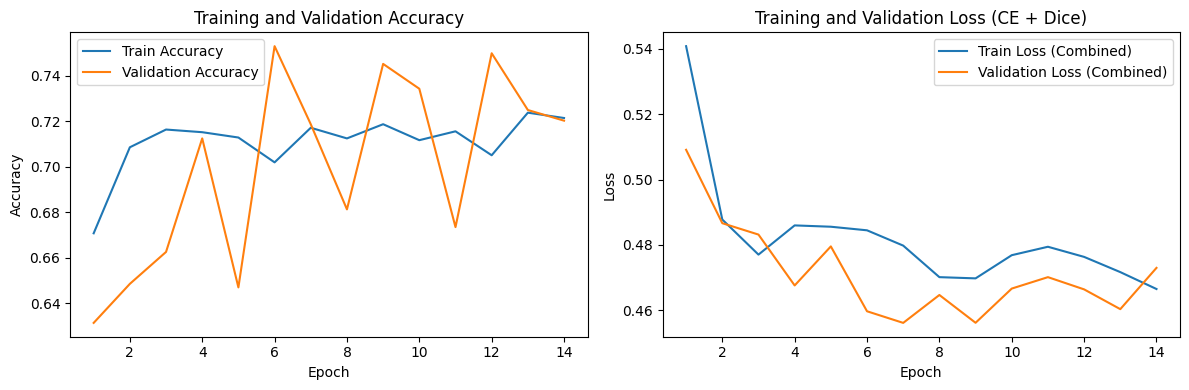

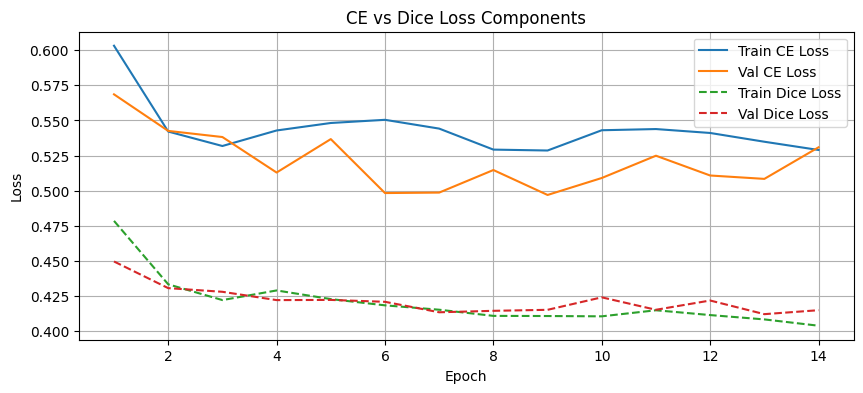


EXTRACTING VGG16 FEATURES


Extracting Features: 100%|██████████| 12/12 [00:11<00:00,  1.05it/s]



Train feature shape: (2560, 4096)
Validation feature shape: (640, 4096)
Test feature shape: (1468, 4096)

TRAINING KNN
KNN training completed.

KNN Validation Accuracy: 0.6922
KNN Test Accuracy: 0.8747

KNN Precision (weighted): 0.8736
KNN Recall (weighted):    0.8747
KNN F1-score (weighted):  0.8692

KNN Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.88      0.96      0.92      1052
  Appears normal       0.86      0.66      0.75       416

        accuracy                           0.87      1468
       macro avg       0.87      0.81      0.83      1468
    weighted avg       0.87      0.87      0.87      1468

KNN Confusion Matrix:
[[1008   44]
 [ 140  276]]


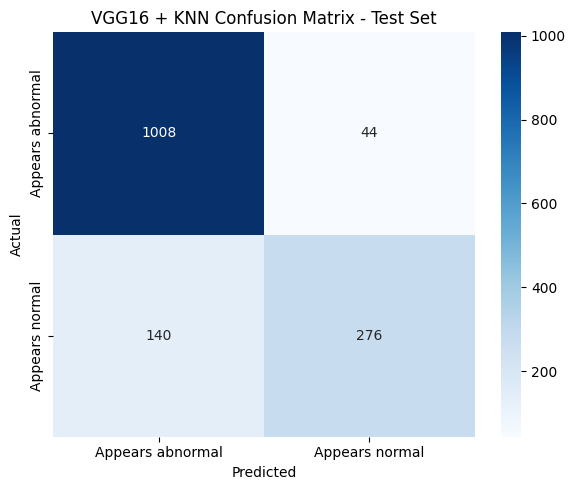


FINAL SUMMARY
Best VGG16 Validation Accuracy: 0.7531
KNN Validation Accuracy: 0.6922
KNN Test Accuracy: 0.8747
KNN Test Precision: 0.8736
KNN Test Recall: 0.8747
KNN Test F1-score: 0.8692

Feature Dimension: 4096

Model Flow:
Input Image -> VGG16 -> 4096-D Features -> KNN -> Prediction


In [22]:
# ============================================================
# IMPORTS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tqdm import tqdm
from datetime import datetime
import os

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# PATHS
# ============================================================

train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# PREPROCESSING
# ============================================================

data_transforms = {

    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}


# ============================================================
# LOAD DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    train_path,
    transform=data_transforms['train']
)

train_dataset_val = datasets.ImageFolder(
    train_path,
    transform=data_transforms['val']
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=data_transforms['test']
)


# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

train_subset = Subset(
    train_dataset,
    train_indices
)

val_subset = Subset(
    train_dataset_val,
    val_indices
)


# ============================================================
# DATALOADERS
# ============================================================

batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)


# ============================================================
# DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth)
            /
            (union + self.smooth)
        )

        return 1. - dice_score.mean()


# ============================================================
# COMBINED LOSS
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# ACCURACY FUNCTION
# ============================================================

def calculate_accuracy(
    y_pred,
    y_true
):

    _, predicted = torch.max(
        y_pred,
        1
    )

    correct = (
        predicted == y_true
    ).sum().item()

    return correct / len(y_true)


# ============================================================
# VGG16 MODEL
# ============================================================

vgg = models.vgg16(
    pretrained=True
)


# Freeze VGG layers

for param in vgg.parameters():
    param.requires_grad = False


# Replace final classifier

vgg.classifier[6] = nn.Linear(
    vgg.classifier[6].in_features,
    num_classes
)


# Move to device

vgg = vgg.to(device)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    vgg.classifier[6].parameters()
)


# ============================================================
# TRAINING SETTINGS
# ============================================================

model_save_path = 'best_vgg_model.pth'

patience = 8

num_epochs = 50


# ============================================================
# GRAPH DATA
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EARLY STOPPING
# ============================================================

best_val_accuracy = 0.0

epochs_no_improve = 0


# ============================================================
# TRAINING
# ============================================================

start = datetime.now()


for epoch in range(num_epochs):

    print("\n" + "=" * 60)

    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print("=" * 60)


    # ========================================================
    # TRAINING PHASE
    # ========================================================

    vgg.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0
    running_accuracy = 0.0


    for inputs, labels_batch in tqdm(
        train_loader,
        desc='Training'
    ):

        inputs = inputs.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = vgg(inputs)

        loss, ce, dice = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        running_accuracy += calculate_accuracy(
            outputs,
            labels_batch
        )


    epoch_train_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_train_ce = (
        running_ce /
        len(train_loader)
    )

    epoch_train_dice = (
        running_dice /
        len(train_loader)
    )

    epoch_train_accuracy = (
        running_accuracy /
        len(train_loader)
    )


    train_losses.append(
        epoch_train_loss
    )

    train_ce_losses.append(
        epoch_train_ce
    )

    train_dice_losses.append(
        epoch_train_dice
    )

    train_accuracies.append(
        epoch_train_accuracy
    )


    print(
        f"Train Loss: {epoch_train_loss:.4f} "
        f"(CE: {epoch_train_ce:.4f}, "
        f"Dice: {epoch_train_dice:.4f}), "
        f"Train Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )


    # ========================================================
    # VALIDATION PHASE
    # ========================================================

    vgg.eval()

    val_loss = 0.0
    val_ce = 0.0
    val_dice = 0.0
    val_accuracy = 0.0


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            val_loader,
            desc='Validating'
        ):

            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)

            outputs = vgg(inputs)

            loss, ce, dice = criterion(
                outputs,
                labels_batch
            )

            val_loss += loss.item()
            val_ce += ce.item()
            val_dice += dice.item()

            val_accuracy += calculate_accuracy(
                outputs,
                labels_batch
            )


    epoch_val_loss = (
        val_loss /
        len(val_loader)
    )

    epoch_val_ce = (
        val_ce /
        len(val_loader)
    )

    epoch_val_dice = (
        val_dice /
        len(val_loader)
    )

    epoch_val_accuracy = (
        val_accuracy /
        len(val_loader)
    )


    val_losses.append(
        epoch_val_loss
    )

    val_ce_losses.append(
        epoch_val_ce
    )

    val_dice_losses.append(
        epoch_val_dice
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    print(
        f"Validation Loss: {epoch_val_loss:.4f} "
        f"(CE: {epoch_val_ce:.4f}, "
        f"Dice: {epoch_val_dice:.4f}), "
        f"Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            epoch_val_accuracy
        )

        epochs_no_improve = 0

        torch.save(
            vgg.state_dict(),
            model_save_path
        )

        print(
            f"  -> Model saved at epoch "
            f"{epoch + 1} with validation "
            f"accuracy {best_val_accuracy:.4f}"
        )

    else:

        epochs_no_improve += 1

        print(
            f"  -> No improvement for "
            f"{epochs_no_improve}/{patience} epochs"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_no_improve >= patience:

        print(
            f"\nEarly stopping triggered at "
            f"epoch {epoch + 1}. "
            f"Best Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )

        break


duration = datetime.now() - start

print(
    "\nTraining completed in time:",
    duration
)


# ============================================================
# LOAD BEST VGG16 MODEL
# ============================================================

vgg.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

vgg = vgg.to(device)

vgg.eval()


print(
    f"\nBest VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)


# ============================================================
# TRAINING & VALIDATION ACCURACY GRAPH
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(12, 4)
)


plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    train_accuracies,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracies,
    label='Validation Accuracy'
)

plt.title(
    'Training and Validation Accuracy'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()


# ============================================================
# TRAINING & VALIDATION LOSS GRAPH
# ============================================================

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.title(
    'Training and Validation Loss (CE + Dice)'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# CE VS DICE LOSS
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    epochs_range,
    train_ce_losses,
    label='Train CE Loss'
)

plt.plot(
    epochs_range,
    val_ce_losses,
    label='Val CE Loss'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.title(
    'CE vs Dice Loss Components'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# VGG16 FEATURE EXTRACTION
# ============================================================

print("\n" + "=" * 60)

print("EXTRACTING VGG16 FEATURES")

print("=" * 60)


# VGG16 feature vector = 4096 dimensions
#
# Input Image
#     ↓
# VGG16 CNN
#     ↓
# Feature Vector
#     ↓
# 4096 features
#     ↓
# KNN


def extract_features(
    model,
    loader
):

    features = []

    labels_list = []

    model.eval()


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            loader,
            desc='Extracting Features'
        ):

            inputs = inputs.to(device)


            # CNN feature extraction

            outputs = model.features(
                inputs
            )

            outputs = model.avgpool(
                outputs
            )

            outputs = torch.flatten(
                outputs,
                1
            )


            # Pass through VGG classifier
            # except final classification layer

            outputs = model.classifier[:6](
                outputs
            )


            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels_batch.numpy()
            )


    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )


    return features, labels_list


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

train_features, train_labels = extract_features(
    vgg,
    train_loader
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

val_features, val_labels = extract_features(
    vgg,
    val_loader
)


# ============================================================
# EXTRACT TEST FEATURES
# ============================================================

test_features, test_labels = extract_features(
    vgg,
    test_loader
)


print(
    "\nTrain feature shape:",
    train_features.shape
)

print(
    "Validation feature shape:",
    val_features.shape
)

print(
    "Test feature shape:",
    test_features.shape
)


# ============================================================
# KNN CLASSIFIER
# ============================================================

print("\n" + "=" * 60)

print("TRAINING KNN")

print("=" * 60)


knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    metric='euclidean',
    n_jobs=-1
)


knn_model.fit(
    train_features,
    train_labels
)


print(
    "KNN training completed."
)


# ============================================================
# KNN VALIDATION
# ============================================================

knn_val_predictions = knn_model.predict(
    val_features
)


knn_val_accuracy = accuracy_score(
    val_labels,
    knn_val_predictions
)


print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# KNN TEST
# ============================================================

knn_test_predictions = knn_model.predict(
    test_features
)


knn_test_accuracy = accuracy_score(
    test_labels,
    knn_test_predictions
)


print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)


# ============================================================
# KNN PRECISION / RECALL / F1
# ============================================================

knn_precision = precision_score(
    test_labels,
    knn_test_predictions,
    average='weighted',
    zero_division=0
)

knn_recall = recall_score(
    test_labels,
    knn_test_predictions,
    average='weighted',
    zero_division=0
)

knn_f1 = f1_score(
    test_labels,
    knn_test_predictions,
    average='weighted',
    zero_division=0
)


print(
    f"\nKNN Precision (weighted): "
    f"{knn_precision:.4f}"
)

print(
    f"KNN Recall (weighted):    "
    f"{knn_recall:.4f}"
)

print(
    f"KNN F1-score (weighted):  "
    f"{knn_f1:.4f}"
)


# ============================================================
# KNN CLASSIFICATION REPORT
# ============================================================

class_names = test_dataset.classes


print(
    "\nKNN Classification Report:"
)

print(
    classification_report(
        test_labels,
        knn_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# KNN CONFUSION MATRIX
# ============================================================

knn_cm = confusion_matrix(
    test_labels,
    knn_test_predictions
)


print(
    "KNN Confusion Matrix:"
)

print(knn_cm)


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title(
    'VGG16 + KNN Confusion Matrix - Test Set'
)

plt.tight_layout()

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)

print("FINAL SUMMARY")

print("=" * 60)


print(
    f"Best VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"KNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)

print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)

print(
    f"KNN Test Precision: "
    f"{knn_precision:.4f}"
)

print(
    f"KNN Test Recall: "
    f"{knn_recall:.4f}"
)

print(
    f"KNN Test F1-score: "
    f"{knn_f1:.4f}"
)

print(
    "\nFeature Dimension:",
    train_features.shape[1]
)

print(
    "\nModel Flow:"
)

print(
    "Input Image"
    " -> VGG16"
    " -> 4096-D Features"
    " -> KNN"
    " -> Prediction"
)

# Naive Bayes

Device: cuda
Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.17s/it]


Train Loss: 0.5234 (CE: 0.5807, Dice: 0.4662), Train Accuracy: 0.6887


...

Validation Loss: 0.4637 (CE: 0.5151, Dice: 0.4123), Validation Accuracy: 0.7047
  -> No improvement for 7/8 epochs

Epoch 18/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.16s/it]


Train Loss: 0.4622 (CE: 0.5214, Dice: 0.4029), Train Accuracy: 0.7242


Validating: 100%|██████████| 5/5 [00:04<00:00,  1.02it/s]


Validation Loss: 0.4636 (CE: 0.5113, Dice: 0.4158), Validation Accuracy: 0.7281
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 18. Best Validation Accuracy: 0.7531

Training completed in time: 0:08:35.435022

Best VGG16 Validation Accuracy: 0.7531


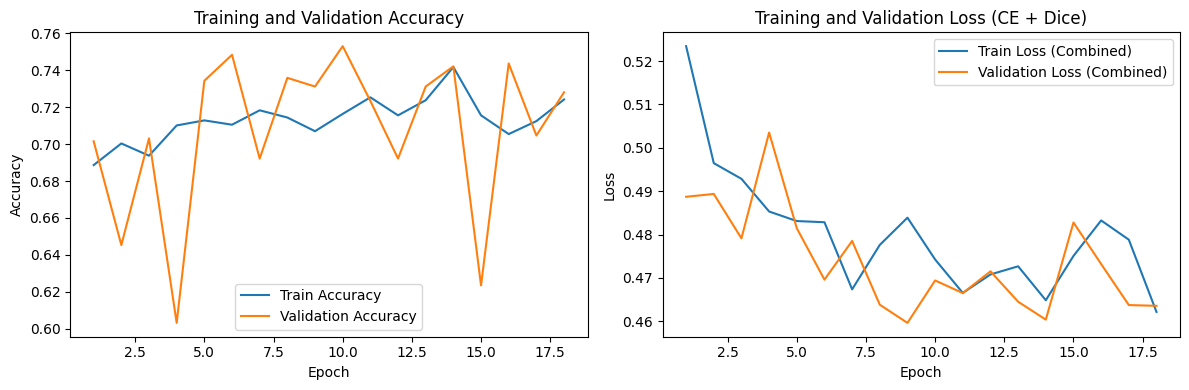

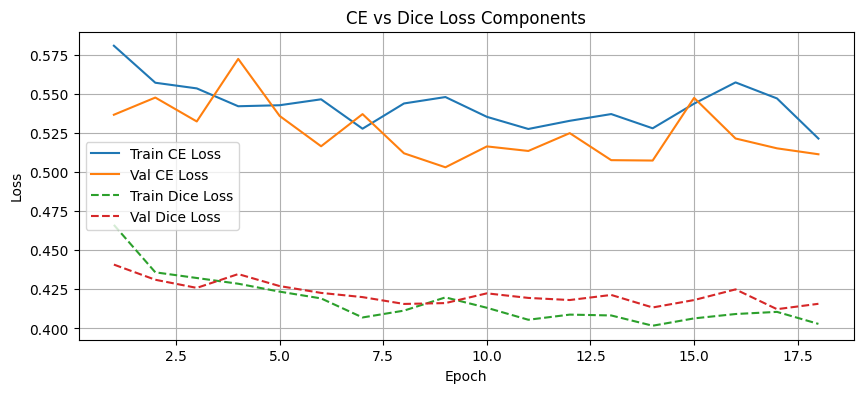


EXTRACTING VGG16 FEATURES


Extracting Features: 100%|██████████| 12/12 [00:11<00:00,  1.04it/s]



Train feature shape: (2560, 4096)
Validation feature shape: (640, 4096)
Test feature shape: (1468, 4096)

TRAINING NAIVE BAYES
Naive Bayes training completed.

Naive Bayes Validation Accuracy: 0.5922
Naive Bayes Test Accuracy: 0.8304

Naive Bayes Precision (weighted): 0.8270
Naive Bayes Recall (weighted):    0.8304
Naive Bayes F1-score (weighted):  0.8282

Naive Bayes Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.87      0.90      0.88      1052
  Appears normal       0.72      0.66      0.69       416

        accuracy                           0.83      1468
       macro avg       0.79      0.78      0.79      1468
    weighted avg       0.83      0.83      0.83      1468

Naive Bayes Confusion Matrix:
[[944 108]
 [141 275]]


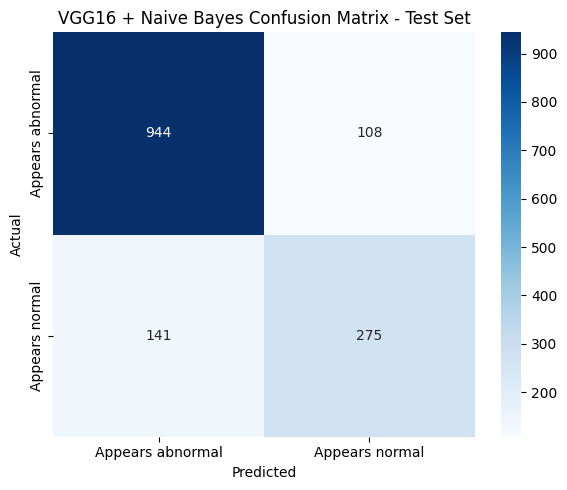


FINAL SUMMARY
Best VGG16 Validation Accuracy: 0.7531
Naive Bayes Validation Accuracy: 0.5922
Naive Bayes Test Accuracy: 0.8304
Naive Bayes Test Precision: 0.8270
Naive Bayes Test Recall: 0.8304
Naive Bayes Test F1-score: 0.8282

Feature Dimension: 4096

Model Flow:
Input Image -> VGG16 -> 4096-D Features -> Naive Bayes -> Prediction


In [23]:
# ============================================================
# IMPORTS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tqdm import tqdm
from datetime import datetime
import os

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# PATHS
# ============================================================

train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# PREPROCESSING
# ============================================================

data_transforms = {

    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}


# ============================================================
# LOAD DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    train_path,
    transform=data_transforms['train']
)

train_dataset_val = datasets.ImageFolder(
    train_path,
    transform=data_transforms['val']
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=data_transforms['test']
)


# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

train_subset = Subset(
    train_dataset,
    train_indices
)

val_subset = Subset(
    train_dataset_val,
    val_indices
)


# ============================================================
# DATALOADERS
# ============================================================

batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)


# ============================================================
# DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth)
            /
            (union + self.smooth)
        )

        return 1. - dice_score.mean()


# ============================================================
# COMBINED LOSS
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# ACCURACY FUNCTION
# ============================================================

def calculate_accuracy(
    y_pred,
    y_true
):

    _, predicted = torch.max(
        y_pred,
        1
    )

    correct = (
        predicted == y_true
    ).sum().item()

    return correct / len(y_true)


# ============================================================
# VGG16 MODEL
# ============================================================

vgg = models.vgg16(
    pretrained=True
)


# Freeze VGG layers

for param in vgg.parameters():
    param.requires_grad = False


# Replace final classifier

vgg.classifier[6] = nn.Linear(
    vgg.classifier[6].in_features,
    num_classes
)


# Move to device

vgg = vgg.to(device)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    vgg.classifier[6].parameters()
)


# ============================================================
# TRAINING SETTINGS
# ============================================================

model_save_path = 'best_vgg_model.pth'

patience = 8

num_epochs = 50


# ============================================================
# GRAPH DATA
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EARLY STOPPING
# ============================================================

best_val_accuracy = 0.0

epochs_no_improve = 0


# ============================================================
# TRAINING
# ============================================================

start = datetime.now()


for epoch in range(num_epochs):

    print("\n" + "=" * 60)

    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print("=" * 60)


    # ========================================================
    # TRAINING PHASE
    # ========================================================

    vgg.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0
    running_accuracy = 0.0


    for inputs, labels_batch in tqdm(
        train_loader,
        desc='Training'
    ):

        inputs = inputs.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = vgg(inputs)

        loss, ce, dice = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        running_accuracy += calculate_accuracy(
            outputs,
            labels_batch
        )


    epoch_train_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_train_ce = (
        running_ce /
        len(train_loader)
    )

    epoch_train_dice = (
        running_dice /
        len(train_loader)
    )

    epoch_train_accuracy = (
        running_accuracy /
        len(train_loader)
    )


    train_losses.append(
        epoch_train_loss
    )

    train_ce_losses.append(
        epoch_train_ce
    )

    train_dice_losses.append(
        epoch_train_dice
    )

    train_accuracies.append(
        epoch_train_accuracy
    )


    print(
        f"Train Loss: {epoch_train_loss:.4f} "
        f"(CE: {epoch_train_ce:.4f}, "
        f"Dice: {epoch_train_dice:.4f}), "
        f"Train Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )


    # ========================================================
    # VALIDATION PHASE
    # ========================================================

    vgg.eval()

    val_loss = 0.0
    val_ce = 0.0
    val_dice = 0.0
    val_accuracy = 0.0


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            val_loader,
            desc='Validating'
        ):

            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)

            outputs = vgg(inputs)

            loss, ce, dice = criterion(
                outputs,
                labels_batch
            )

            val_loss += loss.item()
            val_ce += ce.item()
            val_dice += dice.item()

            val_accuracy += calculate_accuracy(
                outputs,
                labels_batch
            )


    epoch_val_loss = (
        val_loss /
        len(val_loader)
    )

    epoch_val_ce = (
        val_ce /
        len(val_loader)
    )

    epoch_val_dice = (
        val_dice /
        len(val_loader)
    )

    epoch_val_accuracy = (
        val_accuracy /
        len(val_loader)
    )


    val_losses.append(
        epoch_val_loss
    )

    val_ce_losses.append(
        epoch_val_ce
    )

    val_dice_losses.append(
        epoch_val_dice
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    print(
        f"Validation Loss: {epoch_val_loss:.4f} "
        f"(CE: {epoch_val_ce:.4f}, "
        f"Dice: {epoch_val_dice:.4f}), "
        f"Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            epoch_val_accuracy
        )

        epochs_no_improve = 0

        torch.save(
            vgg.state_dict(),
            model_save_path
        )

        print(
            f"  -> Model saved at epoch "
            f"{epoch + 1} with validation "
            f"accuracy {best_val_accuracy:.4f}"
        )

    else:

        epochs_no_improve += 1

        print(
            f"  -> No improvement for "
            f"{epochs_no_improve}/{patience} epochs"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_no_improve >= patience:

        print(
            f"\nEarly stopping triggered at "
            f"epoch {epoch + 1}. "
            f"Best Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )

        break


duration = datetime.now() - start

print(
    "\nTraining completed in time:",
    duration
)


# ============================================================
# LOAD BEST VGG16 MODEL
# ============================================================

vgg.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

vgg = vgg.to(device)

vgg.eval()


print(
    f"\nBest VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)


# ============================================================
# TRAINING & VALIDATION ACCURACY GRAPH
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(12, 4)
)


plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    train_accuracies,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracies,
    label='Validation Accuracy'
)

plt.title(
    'Training and Validation Accuracy'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()


# ============================================================
# TRAINING & VALIDATION LOSS GRAPH
# ============================================================

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.title(
    'Training and Validation Loss (CE + Dice)'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# CE VS DICE LOSS
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    epochs_range,
    train_ce_losses,
    label='Train CE Loss'
)

plt.plot(
    epochs_range,
    val_ce_losses,
    label='Val CE Loss'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.title(
    'CE vs Dice Loss Components'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# VGG16 FEATURE EXTRACTION
# ============================================================

print("\n" + "=" * 60)

print("EXTRACTING VGG16 FEATURES")

print("=" * 60)


# VGG16 feature vector = 4096 dimensions
#
# Input Image
#     ↓
# VGG16
#     ↓
# 4096-D Features
#     ↓
# Gaussian Naive Bayes
#     ↓
# Prediction


def extract_features(
    model,
    loader
):

    features = []

    labels_list = []

    model.eval()


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            loader,
            desc='Extracting Features'
        ):

            inputs = inputs.to(device)


            # CNN feature extraction

            outputs = model.features(
                inputs
            )

            outputs = model.avgpool(
                outputs
            )

            outputs = torch.flatten(
                outputs,
                1
            )


            # VGG classifier layers
            # except final classification layer

            outputs = model.classifier[:6](
                outputs
            )


            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels_batch.numpy()
            )


    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )


    return features, labels_list


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

train_features, train_labels = extract_features(
    vgg,
    train_loader
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

val_features, val_labels = extract_features(
    vgg,
    val_loader
)


# ============================================================
# EXTRACT TEST FEATURES
# ============================================================

test_features, test_labels = extract_features(
    vgg,
    test_loader
)


print(
    "\nTrain feature shape:",
    train_features.shape
)

print(
    "Validation feature shape:",
    val_features.shape
)

print(
    "Test feature shape:",
    test_features.shape
)


# ============================================================
# GAUSSIAN NAIVE BAYES
# ============================================================

print("\n" + "=" * 60)

print("TRAINING NAIVE BAYES")

print("=" * 60)


nb_model = GaussianNB()


nb_model.fit(
    train_features,
    train_labels
)


print(
    "Naive Bayes training completed."
)


# ============================================================
# NAIVE BAYES VALIDATION
# ============================================================

nb_val_predictions = nb_model.predict(
    val_features
)


nb_val_accuracy = accuracy_score(
    val_labels,
    nb_val_predictions
)


print(
    f"\nNaive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)


# ============================================================
# NAIVE BAYES TEST
# ============================================================

nb_test_predictions = nb_model.predict(
    test_features
)


nb_test_accuracy = accuracy_score(
    test_labels,
    nb_test_predictions
)


print(
    f"Naive Bayes Test Accuracy: "
    f"{nb_test_accuracy:.4f}"
)


# ============================================================
# NAIVE BAYES PRECISION / RECALL / F1
# ============================================================

nb_precision = precision_score(
    test_labels,
    nb_test_predictions,
    average='weighted',
    zero_division=0
)

nb_recall = recall_score(
    test_labels,
    nb_test_predictions,
    average='weighted',
    zero_division=0
)

nb_f1 = f1_score(
    test_labels,
    nb_test_predictions,
    average='weighted',
    zero_division=0
)


print(
    f"\nNaive Bayes Precision (weighted): "
    f"{nb_precision:.4f}"
)

print(
    f"Naive Bayes Recall (weighted):    "
    f"{nb_recall:.4f}"
)

print(
    f"Naive Bayes F1-score (weighted):  "
    f"{nb_f1:.4f}"
)


# ============================================================
# NAIVE BAYES CLASSIFICATION REPORT
# ============================================================

class_names = test_dataset.classes


print(
    "\nNaive Bayes Classification Report:"
)

print(
    classification_report(
        test_labels,
        nb_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# NAIVE BAYES CONFUSION MATRIX
# ============================================================

nb_cm = confusion_matrix(
    test_labels,
    nb_test_predictions
)


print(
    "Naive Bayes Confusion Matrix:"
)

print(nb_cm)


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title(
    'VGG16 + Naive Bayes Confusion Matrix - Test Set'
)

plt.tight_layout()

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)

print("FINAL SUMMARY")

print("=" * 60)


print(
    f"Best VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Naive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)

print(
    f"Naive Bayes Test Accuracy: "
    f"{nb_test_accuracy:.4f}"
)

print(
    f"Naive Bayes Test Precision: "
    f"{nb_precision:.4f}"
)

print(
    f"Naive Bayes Test Recall: "
    f"{nb_recall:.4f}"
)

print(
    f"Naive Bayes Test F1-score: "
    f"{nb_f1:.4f}"
)

print(
    "\nFeature Dimension:",
    train_features.shape[1]
)

print(
    "\nModel Flow:"
)

print(
    "Input Image"
    " -> VGG16"
    " -> 4096-D Features"
    " -> Naive Bayes"
    " -> Prediction"
)

# Adaboost

Device: cuda
Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.16s/it]


Train Loss: 0.5644 (CE: 0.6381, Dice: 0.4907), Train Accuracy: 0.6613


...

Validation Loss: 0.4650 (CE: 0.5155, Dice: 0.4144), Validation Accuracy: 0.7094
  -> No improvement for 7/8 epochs

Epoch 16/50


Training: 100%|██████████| 20/20 [00:23<00:00,  1.19s/it]


Train Loss: 0.4709 (CE: 0.5342, Dice: 0.4076), Train Accuracy: 0.7211


Validating: 100%|██████████| 5/5 [00:04<00:00,  1.02it/s]


Validation Loss: 0.4725 (CE: 0.5197, Dice: 0.4253), Validation Accuracy: 0.7469
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 16. Best Validation Accuracy: 0.7531

Training completed in time: 0:07:39.614982

Best VGG16 Validation Accuracy: 0.7531


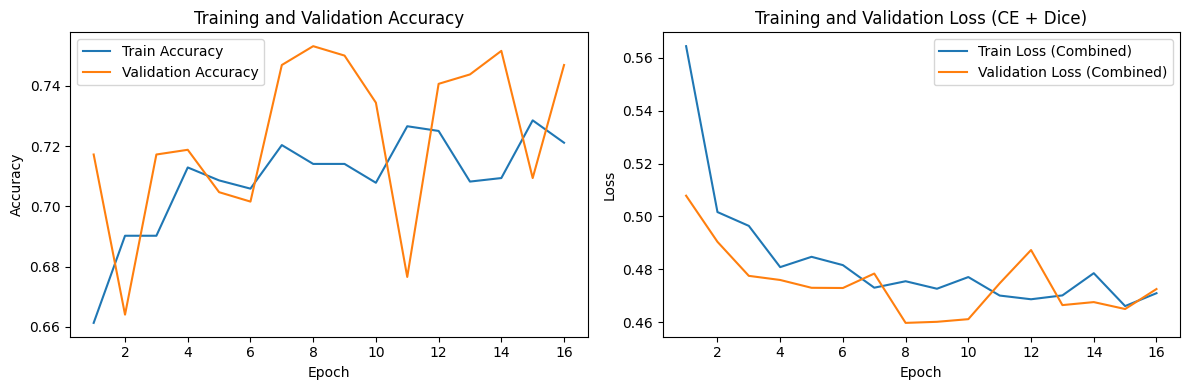

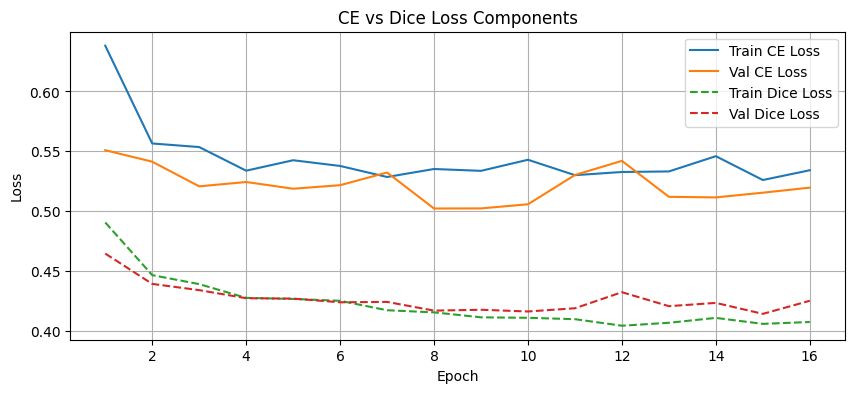


EXTRACTING VGG16 FEATURES


Extracting Features: 100%|██████████| 12/12 [00:11<00:00,  1.04it/s]



Train feature shape: (2560, 4096)
Validation feature shape: (640, 4096)
Test feature shape: (1468, 4096)

TRAINING ADABOOST
AdaBoost training completed.

AdaBoost Validation Accuracy: 0.6766
AdaBoost Test Accuracy: 0.7663

AdaBoost Precision (weighted): 0.7634
AdaBoost Recall (weighted):    0.7663
AdaBoost F1-score (weighted):  0.7232

AdaBoost Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.77      0.97      0.86      1052
  Appears normal       0.75      0.26      0.39       416

        accuracy                           0.77      1468
       macro avg       0.76      0.61      0.62      1468
    weighted avg       0.76      0.77      0.72      1468

AdaBoost Confusion Matrix:
[[1016   36]
 [ 307  109]]


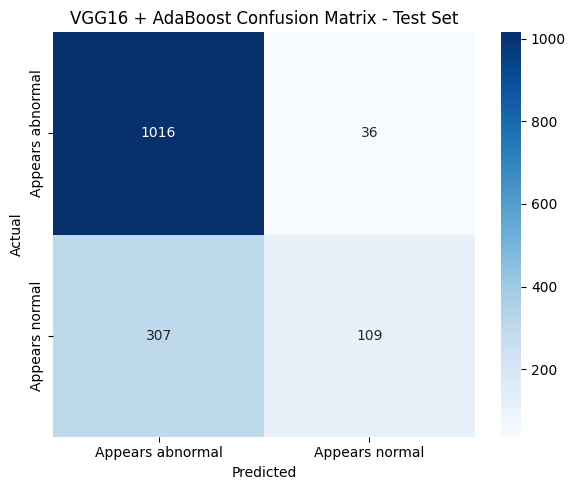


FINAL SUMMARY
Best VGG16 Validation Accuracy: 0.7531
AdaBoost Validation Accuracy: 0.6766
AdaBoost Test Accuracy: 0.7663
AdaBoost Test Precision: 0.7634
AdaBoost Test Recall: 0.7663
AdaBoost Test F1-score: 0.7232

Feature Dimension: 4096

Model Flow:
Input Image -> VGG16 -> 4096-D Features -> AdaBoost -> Prediction


In [24]:
# ============================================================
# IMPORTS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tqdm import tqdm
from datetime import datetime
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# PATHS
# ============================================================

train_path = '/kaggle/working/PCOSGen-train/train'
test_path = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# PREPROCESSING
# ============================================================

data_transforms = {

    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(40),
        transforms.RandomHorizontalFlip(),
        transforms.RandomResizedCrop(224),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}


# ============================================================
# LOAD DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    train_path,
    transform=data_transforms['train']
)

train_dataset_val = datasets.ImageFolder(
    train_path,
    transform=data_transforms['val']
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=data_transforms['test']
)


# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

train_subset = Subset(
    train_dataset,
    train_indices
)

val_subset = Subset(
    train_dataset_val,
    val_indices
)


# ============================================================
# DATALOADERS
# ============================================================

batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)


# ============================================================
# DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            (2. * intersection + self.smooth)
            /
            (union + self.smooth)
        )

        return 1. - dice_score.mean()


# ============================================================
# COMBINED LOSS
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# ACCURACY FUNCTION
# ============================================================

def calculate_accuracy(
    y_pred,
    y_true
):

    _, predicted = torch.max(
        y_pred,
        1
    )

    correct = (
        predicted == y_true
    ).sum().item()

    return correct / len(y_true)


# ============================================================
# VGG16 MODEL
# ============================================================

vgg = models.vgg16(
    pretrained=True
)


# Freeze VGG layers

for param in vgg.parameters():
    param.requires_grad = False


# Replace final classifier

vgg.classifier[6] = nn.Linear(
    vgg.classifier[6].in_features,
    num_classes
)


# Move to device

vgg = vgg.to(device)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    vgg.classifier[6].parameters()
)


# ============================================================
# TRAINING SETTINGS
# ============================================================

model_save_path = 'best_vgg_model.pth'

patience = 8

num_epochs = 50


# ============================================================
# GRAPH DATA
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EARLY STOPPING
# ============================================================

best_val_accuracy = 0.0

epochs_no_improve = 0


# ============================================================
# TRAINING
# ============================================================

start = datetime.now()


for epoch in range(num_epochs):

    print("\n" + "=" * 60)

    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print("=" * 60)


    # ========================================================
    # TRAINING PHASE
    # ========================================================

    vgg.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0
    running_accuracy = 0.0


    for inputs, labels_batch in tqdm(
        train_loader,
        desc='Training'
    ):

        inputs = inputs.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = vgg(inputs)

        loss, ce, dice = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        running_accuracy += calculate_accuracy(
            outputs,
            labels_batch
        )


    epoch_train_loss = (
        running_loss /
        len(train_loader)
    )

    epoch_train_ce = (
        running_ce /
        len(train_loader)
    )

    epoch_train_dice = (
        running_dice /
        len(train_loader)
    )

    epoch_train_accuracy = (
        running_accuracy /
        len(train_loader)
    )


    train_losses.append(
        epoch_train_loss
    )

    train_ce_losses.append(
        epoch_train_ce
    )

    train_dice_losses.append(
        epoch_train_dice
    )

    train_accuracies.append(
        epoch_train_accuracy
    )


    print(
        f"Train Loss: {epoch_train_loss:.4f} "
        f"(CE: {epoch_train_ce:.4f}, "
        f"Dice: {epoch_train_dice:.4f}), "
        f"Train Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )


    # ========================================================
    # VALIDATION PHASE
    # ========================================================

    vgg.eval()

    val_loss = 0.0
    val_ce = 0.0
    val_dice = 0.0
    val_accuracy = 0.0


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            val_loader,
            desc='Validating'
        ):

            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)

            outputs = vgg(inputs)

            loss, ce, dice = criterion(
                outputs,
                labels_batch
            )

            val_loss += loss.item()
            val_ce += ce.item()
            val_dice += dice.item()

            val_accuracy += calculate_accuracy(
                outputs,
                labels_batch
            )


    epoch_val_loss = (
        val_loss /
        len(val_loader)
    )

    epoch_val_ce = (
        val_ce /
        len(val_loader)
    )

    epoch_val_dice = (
        val_dice /
        len(val_loader)
    )

    epoch_val_accuracy = (
        val_accuracy /
        len(val_loader)
    )


    val_losses.append(
        epoch_val_loss
    )

    val_ce_losses.append(
        epoch_val_ce
    )

    val_dice_losses.append(
        epoch_val_dice
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    print(
        f"Validation Loss: {epoch_val_loss:.4f} "
        f"(CE: {epoch_val_ce:.4f}, "
        f"Dice: {epoch_val_dice:.4f}), "
        f"Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            epoch_val_accuracy
        )

        epochs_no_improve = 0

        torch.save(
            vgg.state_dict(),
            model_save_path
        )

        print(
            f"  -> Model saved at epoch "
            f"{epoch + 1} with validation "
            f"accuracy {best_val_accuracy:.4f}"
        )

    else:

        epochs_no_improve += 1

        print(
            f"  -> No improvement for "
            f"{epochs_no_improve}/{patience} epochs"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_no_improve >= patience:

        print(
            f"\nEarly stopping triggered at "
            f"epoch {epoch + 1}. "
            f"Best Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )

        break


duration = datetime.now() - start

print(
    "\nTraining completed in time:",
    duration
)


# ============================================================
# LOAD BEST VGG16 MODEL
# ============================================================

vgg.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

vgg = vgg.to(device)

vgg.eval()


print(
    f"\nBest VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)


# ============================================================
# TRAINING & VALIDATION ACCURACY GRAPH
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(12, 4)
)


plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    train_accuracies,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accuracies,
    label='Validation Accuracy'
)

plt.title(
    'Training and Validation Accuracy'
)

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()


# ============================================================
# TRAINING & VALIDATION LOSS GRAPH
# ============================================================

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Validation Loss (Combined)'
)

plt.title(
    'Training and Validation Loss (CE + Dice)'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# CE VS DICE LOSS
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    epochs_range,
    train_ce_losses,
    label='Train CE Loss'
)

plt.plot(
    epochs_range,
    val_ce_losses,
    label='Val CE Loss'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.title(
    'CE vs Dice Loss Components'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# VGG16 FEATURE EXTRACTION
# ============================================================

print("\n" + "=" * 60)

print("EXTRACTING VGG16 FEATURES")

print("=" * 60)


# VGG16 feature vector = 4096 dimensions
#
# Input Image
#     ↓
# VGG16
#     ↓
# 4096-D Features
#     ↓
# AdaBoost
#     ↓
# Prediction


def extract_features(
    model,
    loader
):

    features = []

    labels_list = []

    model.eval()


    with torch.no_grad():

        for inputs, labels_batch in tqdm(
            loader,
            desc='Extracting Features'
        ):

            inputs = inputs.to(device)


            # CNN feature extraction

            outputs = model.features(
                inputs
            )

            outputs = model.avgpool(
                outputs
            )

            outputs = torch.flatten(
                outputs,
                1
            )


            # VGG classifier layers
            # except final classification layer

            outputs = model.classifier[:6](
                outputs
            )


            features.append(
                outputs.cpu().numpy()
            )

            labels_list.append(
                labels_batch.numpy()
            )


    features = np.concatenate(
        features,
        axis=0
    )

    labels_list = np.concatenate(
        labels_list,
        axis=0
    )


    return features, labels_list


# ============================================================
# EXTRACT TRAIN FEATURES
# ============================================================

train_features, train_labels = extract_features(
    vgg,
    train_loader
)


# ============================================================
# EXTRACT VALIDATION FEATURES
# ============================================================

val_features, val_labels = extract_features(
    vgg,
    val_loader
)


# ============================================================
# EXTRACT TEST FEATURES
# ============================================================

test_features, test_labels = extract_features(
    vgg,
    test_loader
)


print(
    "\nTrain feature shape:",
    train_features.shape
)

print(
    "Validation feature shape:",
    val_features.shape
)

print(
    "Test feature shape:",
    test_features.shape
)


# ============================================================
# ADABOOST CLASSIFIER
# ============================================================

print("\n" + "=" * 60)

print("TRAINING ADABOOST")

print("=" * 60)


base_estimator = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)


ada_model = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)


ada_model.fit(
    train_features,
    train_labels
)


print(
    "AdaBoost training completed."
)


# ============================================================
# ADABOOST VALIDATION
# ============================================================

ada_val_predictions = ada_model.predict(
    val_features
)


ada_val_accuracy = accuracy_score(
    val_labels,
    ada_val_predictions
)


print(
    f"\nAdaBoost Validation Accuracy: "
    f"{ada_val_accuracy:.4f}"
)


# ============================================================
# ADABOOST TEST
# ============================================================

ada_test_predictions = ada_model.predict(
    test_features
)


ada_test_accuracy = accuracy_score(
    test_labels,
    ada_test_predictions
)


print(
    f"AdaBoost Test Accuracy: "
    f"{ada_test_accuracy:.4f}"
)


# ============================================================
# ADABOOST PRECISION / RECALL / F1
# ============================================================

ada_precision = precision_score(
    test_labels,
    ada_test_predictions,
    average='weighted',
    zero_division=0
)

ada_recall = recall_score(
    test_labels,
    ada_test_predictions,
    average='weighted',
    zero_division=0
)

ada_f1 = f1_score(
    test_labels,
    ada_test_predictions,
    average='weighted',
    zero_division=0
)


print(
    f"\nAdaBoost Precision (weighted): "
    f"{ada_precision:.4f}"
)

print(
    f"AdaBoost Recall (weighted):    "
    f"{ada_recall:.4f}"
)

print(
    f"AdaBoost F1-score (weighted):  "
    f"{ada_f1:.4f}"
)


# ============================================================
# ADABOOST CLASSIFICATION REPORT
# ============================================================

class_names = test_dataset.classes


print(
    "\nAdaBoost Classification Report:"
)

print(
    classification_report(
        test_labels,
        ada_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# ADABOOST CONFUSION MATRIX
# ============================================================

ada_cm = confusion_matrix(
    test_labels,
    ada_test_predictions
)


print(
    "AdaBoost Confusion Matrix:"
)

print(ada_cm)


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    ada_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title(
    'VGG16 + AdaBoost Confusion Matrix - Test Set'
)

plt.tight_layout()

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)

print("FINAL SUMMARY")

print("=" * 60)


print(
    f"Best VGG16 Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"AdaBoost Validation Accuracy: "
    f"{ada_val_accuracy:.4f}"
)

print(
    f"AdaBoost Test Accuracy: "
    f"{ada_test_accuracy:.4f}"
)

print(
    f"AdaBoost Test Precision: "
    f"{ada_precision:.4f}"
)

print(
    f"AdaBoost Test Recall: "
    f"{ada_recall:.4f}"
)

print(
    f"AdaBoost Test F1-score: "
    f"{ada_f1:.4f}"
)

print(
    "\nFeature Dimension:",
    train_features.shape[1]
)

print(
    "\nModel Flow:"
)

print(
    "Input Image"
    " -> VGG16"
    " -> 4096-D Features"
    " -> AdaBoost"
    " -> Prediction"
)